# Práctica 2 (Parcial 2) — Implementación con Deep Learning
## Detección de fallas en equipos de refrigeración con redes neuronales artificiales

| Elemento | Descripción |
|---|---|
| **Asignatura** | Inteligencia Artificial |
| **Tema principal** | Aprendizaje profundo (Deep Learning) |
| **Técnica** | Redes neuronales artificiales |
| **Lenguaje** | Python |
| **Entorno** | Google Colab |
| **Biblioteca** | TensorFlow / Keras |
| **Duración** | 3 a 4 horas |
| **Producto final** | Detector de fallas en refrigeración |

---

## 1. Objetivo general

Desarrollar un modelo de aprendizaje profundo (Deep Learning) mediante una red neuronal artificial, capaz de identificar condiciones normales y posibles fallas en equipos industriales de refrigeración, utilizando datos simulados de temperatura, vibración, consumo eléctrico, presión y apertura de puertas.

## 2. Planteamiento del problema

Una empresa de alimentos congelados cuenta con una cámara de refrigeración industrial que debe mantener sus productos a una temperatura aproximada de **-20 °C**.

Actualmente, los técnicos realizan inspecciones manuales para identificar problemas en los equipos. Sin embargo, algunas fallas no son detectadas oportunamente y pueden provocar:

- Pérdida de temperatura de conservación.
- Deterioro de alimentos congelados.
- Incremento en el consumo eléctrico.
- Daños en compresores.
- Costos adicionales por mantenimiento correctivo.

La empresa desea implementar un prototipo de inteligencia artificial que analice los parámetros de funcionamiento de sus equipos y determine si existe alguna condición anormal.

**La solución propuesta:** entrenar una red neuronal artificial con registros históricos simulados para que aprenda a reconocer **cuatro condiciones de operación**.

## 3. Tipos de condiciones que identificará el sistema

| Condición | Significado | Patrón típico simulado |
|---|---|---|
| **NORMAL** | Equipo funcionando correctamente | ≈ -20 °C, vibración baja, corriente estable, presión ≈ 2.2 bar |
| **COMPRESOR** | Posible falla del compresor | Temperatura sube a ≈ -12 °C, vibración y corriente altas, presión alta |
| **FUGA** | Posible fuga de refrigerante | Temperatura ≈ -14 °C, presión muy baja (≈ 1.2 bar), corriente baja |
| **PUERTA** | Problema de puerta o aislamiento | Temperatura ≈ -10 °C y apertura prolongada de la puerta (≈ 18 min) |

> **Nota didáctica:** las condiciones y sus patrones serán simulados para fines educativos. En una instalación real, los síntomas pueden coincidir entre diferentes fallas y deben validarse con mediciones, documentación técnica y personal especializado.

---

## 4. ¿Cómo funcionará el sistema?

Desarrollaremos un proceso de **aprendizaje supervisado** mediante una red neuronal:

1. Se generan registros simulados etiquetados con la condición real (NORMAL, COMPRESOR, FUGA o PUERTA).
2. La red recibe las cinco variables de entrada y genera una predicción.
3. Se compara la predicción con la categoría real y se calcula el error.
4. El algoritmo Adam ajusta los pesos de las conexiones y el proceso se repite (épocas).
5. Una vez entrenada, la red recibe los valores de un equipo nuevo y predice su condición con un porcentaje de confianza.

---

## 5. Preparación del entorno de trabajo

Trabajaremos con **Google Colab** para evitar instalaciones complicadas.

**Paso 1.** Abrir Google Colab, crear un nuevo cuaderno y asignarle el nombre:
`Practica_DeepLearning_Refrigeracion.ipynb`

**Paso 2.** Instalar e importar bibliotecas.

En la primera celda, ejecutar:

In [ ]:
# Paso 1: Instalar las bibliotecas necesarias
!pip install -q tensorflow scikit-learn pandas matplotlib

In [ ]:
# Paso 2: Importar las bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("TensorFlow:", tf.__version__)
print("Entorno preparado correctamente")

TensorFlow: 2.21.0
Entorno preparado correctamente


**¿Qué hace cada biblioteca?**

| Biblioteca | Utilidad |
|---|---|
| NumPy | Generación y manipulación de datos numéricos. |
| Pandas | Creación y análisis de tablas. |
| Matplotlib | Elaboración de gráficas. |
| TensorFlow | Construcción y entrenamiento de la red neuronal. |
| Scikit-learn | Preparación y evaluación de los datos. |

---

## 6. Construcción del conjunto de datos

**Paso 3.** Definir las variables de los equipos de refrigeración.

El sistema trabajará con cinco variables:

| Variable | Unidad | Qué representa |
|---|---|---|
| temperatura | °C | Temperatura interna del refrigerador. |
| vibración | mm/s | Nivel de vibración del compresor. |
| corriente | A | Consumo eléctrico del equipo. |
| presión | bar | Presión de operación del circuito. |
| apertura | minutos | Tiempo de apertura de la puerta. |

Cada registro representará una medición del equipo en un momento determinado.

**Paso 4.** Generar datos simulados.

Como no contamos con sensores físicos ni registros industriales, generaremos **2,800 registros simulados**. El código creará ejemplos de las cuatro condiciones que queremos reconocer.

In [ ]:
# Paso 4: Generar datos simulados (2,800 registros: 700 por condición)
np.random.seed(42)  # Semilla para que los datos sean reproducibles

datos = []


def generar_datos(nombre, temperatura, vibracion, corriente, presion, apertura):
    # Genera 700 registros simulados de una condicion de operacion
    for _ in range(700):
        datos.append({
            "temperatura": np.random.normal(temperatura[0], temperatura[1]),
            "vibracion": np.random.normal(vibracion[0], vibracion[1]),
            "corriente": np.random.normal(corriente[0], corriente[1]),
            "presion": np.random.normal(presion[0], presion[1]),
            "apertura": np.random.normal(apertura[0], apertura[1]),
            "falla": nombre,
        })


# 1. Equipo funcionando normalmente
generar_datos(
    "NORMAL",
    (-20, 2),      # temperatura media y desviacion
    (2, 0.6),      # vibracion
    (8, 1),        # corriente
    (2.2, 0.25),   # presion
    (3, 2),        # apertura de puerta
)

# 2. Posible falla del compresor
generar_datos(
    "COMPRESOR",
    (-12, 2.5),
    (6, 1.3),
    (12, 1.8),
    (3.1, 0.5),
    (4, 2),
)

# 3. Posible fuga de refrigerante
generar_datos(
    "FUGA",
    (-14, 2),
    (2.8, 0.7),
    (6.5, 1),
    (1.2, 0.3),
    (4, 2),
)

# 4. Problema de puerta o aislamiento
generar_datos(
    "PUERTA",
    (-10, 2.5),
    (2.2, 0.7),
    (8.5, 1),
    (2.1, 0.3),
    (18, 5),
)

# Crear DataFrame
df = pd.DataFrame(datos)

# Limitar valores a rangos fisicos simulados
df["temperatura"] = df["temperatura"].clip(-30, 0)
df["vibracion"] = df["vibracion"].clip(0.1, 15)
df["corriente"] = df["corriente"].clip(0.5, 20)
df["presion"] = df["presion"].clip(0.1, 6)
df["apertura"] = df["apertura"].clip(0, 30)

# Mezclar los registros
df = df.sample(frac=1, random_state=42).reset_index(drop=True)

print("Datos generados correctamente")
print(df.head())

Datos generados correctamente
   temperatura  vibracion  corriente   presion   apertura      falla
0   -13.504861   5.176799  10.468896  2.829497   5.511332  COMPRESOR
1   -13.129873   4.973860  11.987319  2.992195   3.256284  COMPRESOR
2   -11.652103   1.797369   8.488099  1.907956  20.540061     PUERTA
3   -14.031364   8.736887  12.062798  2.412245   6.736159  COMPRESOR
4   -11.067115   1.813549   4.967402  1.280792   6.298975       FUGA


**¿Qué debes observar?**

El conjunto de datos tendrá **2,800 registros** y **seis columnas**: cinco variables de medición y una columna que indica el tipo de condición.

Por ejemplo:

| Temperatura | Vibración | Corriente | Presión | Apertura | Falla |
|---|---|---|---|---|---|
| -20.5 | 2.1 | 8.2 | 2.2 | 2.5 | NORMAL |
| -11.8 | 6.4 | 12.3 | 3.0 | 4.2 | COMPRESOR |
| -14.2 | 2.7 | 6.1 | 1.1 | 3.8 | FUGA |
| -9.8 | 2.3 | 8.6 | 2.0 | 19.5 | PUERTA |

*Los valores de esta tabla son ilustrativos; el programa generará los registros concretos.*

**Paso 5.** Conocer la distribución de los datos:

In [ ]:
# Paso 5: Distribucion de los datos
print("Dimensiones del conjunto:")
print(df.shape)

print("\nCantidad de registros por condicion:")
print(df["falla"].value_counts())

print("\nEstadisticas generales:")
print(df.describe())

Dimensiones del conjunto:
(2800, 6)

Cantidad de registros por condicion:
falla
COMPRESOR    700
PUERTA       700
FUGA         700
NORMAL       700
Name: count, dtype: int64

Estadisticas generales:
       temperatura    vibracion    corriente      presion     apertura
count  2800.000000  2800.000000  2800.000000  2800.000000  2800.000000
mean    -13.986497     3.255311     8.726795     2.139202     7.336368
std       4.379554     1.830859     2.391354     0.750023     6.890787
min     -25.406465     0.100000     2.898915     0.317058     0.000000
25%     -17.210095     2.008736     7.082972     1.625579     2.867742
50%     -13.371848     2.654656     8.209543     2.144534     4.605607
75%     -10.733296     3.973996     9.796406     2.535201     8.446003
max      -1.427724    10.587772    17.673702     4.567703    30.000000


Debes comprobar que existen **700 registros de cada condición**.

---

## 7. Visualización de los datos

**Paso 6.** Elaborar gráficas para comprender el comportamiento.

Antes de entrenar la red neuronal, debes identificar diferencias entre las condiciones.

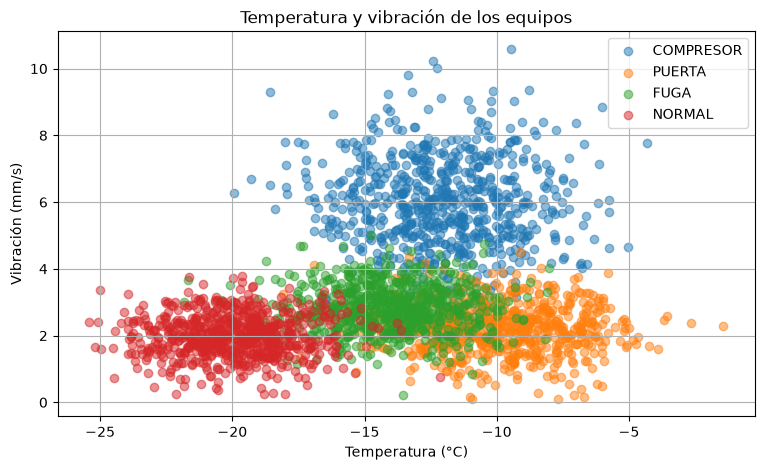

In [ ]:
# Paso 6: Grafica de temperatura vs vibracion por condicion
plt.figure(figsize=(9, 5))

for falla in df["falla"].unique():
    subconjunto = df[df["falla"] == falla]
    plt.scatter(
        subconjunto["temperatura"],
        subconjunto["vibracion"],
        label=falla,
        alpha=0.5,
    )

plt.xlabel("Temperatura (°C)")
plt.ylabel("Vibración (mm/s)")
plt.title("Temperatura y vibración de los equipos")
plt.legend()
plt.grid()
plt.show()

### Actividad de interpretación

Antes de continuar, responde en tu documento de entrega:

1. ¿Qué condición presenta temperaturas más elevadas?
2. ¿Qué condición presenta mayor vibración?
3. ¿Es posible distinguir las fallas utilizando únicamente una variable?
4. ¿Por qué conviene utilizar varias variables simultáneamente?

*Esta actividad permite explicar por qué las redes neuronales pueden aprender relaciones entre diferentes características.*

---

## 8. Preparación de los datos para Deep Learning

Aquí comienza una parte fundamental: transformar los datos para que puedan ser procesados por la red neuronal.

**Paso 7.** Separar las variables predictoras y la variable objetivo.

Las variables predictoras serán los cinco parámetros de funcionamiento. La variable objetivo será el tipo de falla.

In [ ]:
# Paso 7: Variables de entrada y variable objetivo
X = df[
    [
        "temperatura",
        "vibracion",
        "corriente",
        "presion",
        "apertura",
    ]
]

# Variable que queremos predecir
y = df["falla"]

print("Variables de entrada:")
print(X.head())

print("\nCondiciones que aprendera la red:")
print(y.unique())

Variables de entrada:
   temperatura  vibracion  corriente   presion   apertura
0   -13.504861   5.176799  10.468896  2.829497   5.511332
1   -13.129873   4.973860  11.987319  2.992195   3.256284
2   -11.652103   1.797369   8.488099  1.907956  20.540061
3   -14.031364   8.736887  12.062798  2.412245   6.736159
4   -11.067115   1.813549   4.967402  1.280792   6.298975

Condiciones que aprendera la red:
<StringArray>
['COMPRESOR', 'PUERTA', 'FUGA', 'NORMAL']
Length: 4, dtype: str


**Paso 8.** Convertir las categorías en valores numéricos.

La red neuronal necesita etiquetas numéricas.

In [ ]:
# Paso 8: Codificar las etiquetas de clase
codificador = LabelEncoder()
y_codificado = codificador.fit_transform(y)

print("Correspondencia de las clases:")
for numero, nombre in enumerate(codificador.classes_):
    print(numero, "=", nombre)

Correspondencia de las clases:
0 = COMPRESOR
1 = FUGA
2 = NORMAL
3 = PUERTA


El resultado tendrá cuatro categorías numéricas, correspondientes a las cuatro condiciones.

**Paso 9.** Dividir los datos para entrenamiento y pruebas.

Separaremos el **80%** de los datos para entrenar el modelo y el **20%** para comprobar su funcionamiento.

In [ ]:
# Paso 9: Dividir en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_codificado,
    test_size=0.20,
    random_state=42,
    stratify=y_codificado,
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (2240, 5)
Datos de prueba: (560, 5)


**Paso 10.** Normalizar las variables.

Las variables tienen diferentes unidades y escalas. Por ejemplo, la temperatura puede ser -20 y la vibración 2.

Por ello, debemos normalizar los datos.

In [ ]:
# Paso 10: Normalizar (escalar) las variables
escalador = StandardScaler()
X_train = escalador.fit_transform(X_train)
X_test = escalador.transform(X_test)

print("Datos normalizados correctamente")

Datos normalizados correctamente


> Es importante que el escalador se ajuste **únicamente con los datos de entrenamiento** para evitar filtrar información del conjunto de prueba.

---

## 9. Construcción de la red neuronal artificial

Esta es la parte central de la práctica.

**Paso 11.** Crear la arquitectura de Deep Learning.

La red neuronal estará integrada por:

- Una capa de **entrada** con cinco neuronas, una por cada variable.
- Una primera capa **oculta** con 32 neuronas.
- Una segunda capa **oculta** con 16 neuronas.
- Una capa de **salida** con cuatro neuronas, una por cada condición.

**Paso 12.** Programar la red neuronal.

In [ ]:
# Paso 12: Crear y configurar la red neuronal
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Crear la red neuronal
modelo = Sequential([
    # Entrada: cinco variables
    Input(shape=(5,)),

    # Primera capa oculta
    Dense(32, activation="relu"),

    # Regularizacion para reducir sobreajuste
    Dropout(0.15),

    # Segunda capa oculta
    Dense(16, activation="relu"),

    # Capa de salida: cuatro condiciones
    Dense(4, activation="softmax"),
])

# Configurar el aprendizaje
modelo.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Mostrar arquitectura
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 788 (3.08 KB)

 Trainable params: 788 (3.08 KB)

 Non-trainable params: 0 (0.00 B)

**Explicación de los elementos:**

| Elemento | Función |
|---|---|
| **Dense** | Crea una capa de neuronas conectadas. |
| **ReLU** | Función de activación de las capas ocultas. |
| **Dropout** | Desactiva aleatoriamente algunas conexiones durante el entrenamiento para reducir el sobreajuste. |
| **Softmax** | Calcula las probabilidades de las cuatro categorías. |
| **Adam** | Algoritmo que ajusta los pesos de la red neuronal. |
| **Loss** | Mide el error de las predicciones. |
| **Accuracy** | Calcula la proporción de clasificaciones correctas. |

Aquí podemos explicar que las neuronas reciben información, realizan operaciones matemáticas y transmiten resultados a otras neuronas.

---

## 10. Entrenamiento de la red neuronal

**Paso 13.** Entrenar el modelo.

El entrenamiento permitirá que la red neuronal aprenda a reconocer patrones asociados con las diferentes condiciones de refrigeración. Utilizaremos **50 épocas** como máximo.

**¿Qué sucede durante el entrenamiento?**

1. La red recibe los datos de temperatura, vibración, corriente, presión y apertura.
2. Las neuronas realizan cálculos.
3. La red genera una predicción.
4. Se compara la predicción con la categoría real.
5. Se calcula el error.
6. El algoritmo Adam ajusta los pesos de las conexiones.
7. El proceso se repite hasta mejorar el aprendizaje o detenerse por el criterio establecido.

Esto permite demostrar el funcionamiento del aprendizaje profundo mediante múltiples capas de neuronas.

In [ ]:
# Paso 13: Entrenar la red neuronal
# Detener el entrenamiento si no mejora
detener = EarlyStopping(
    monitor="val_loss",
    patience=6,
    restore_best_weights=True,
)

# Entrenamiento
historial = modelo.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.20,
    callbacks=[detener],
    verbose=1,
)

Epoch 1/50



 1/56 ━━━━━━━━━━━━━━━━━━━━ 1:07 1s/step - accuracy: 0.3125 - loss: 1.3579


32/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.4258 - loss: 1.2696 


56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5179 - loss: 1.1480 - val_accuracy: 0.8393 - val_loss: 0.8086


Epoch 2/50



 1/56 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8438 - loss: 0.7785

... (193 outputs left out)

Epoch 50/50



 1/56 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy: 1.0000 - loss: 7.5264e-04


31/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9990 - loss: 0.0091     


56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9983 - loss: 0.0089 - val_accuracy: 0.9933 - val_loss: 0.0126


---

## 11. Evaluación del aprendizaje

**Paso 14.** Comprobar el rendimiento.

Una vez entrenada la red, debemos verificar si puede reconocer condiciones que no utilizó durante el entrenamiento.

In [ ]:
# Paso 14: Evaluar el modelo con el conjunto de prueba
perdida, precision = modelo.evaluate(X_test, y_test, verbose=0)

print("Perdida del modelo:", perdida)
print("Precision del modelo:", precision * 100, "%")

Perdida del modelo: 0.00630444660782814
Precision del modelo: 99.46428537368774 %


La precisión representa el porcentaje de registros clasificados correctamente dentro del conjunto de prueba.

**Paso 15.** Visualizar el comportamiento del entrenamiento.

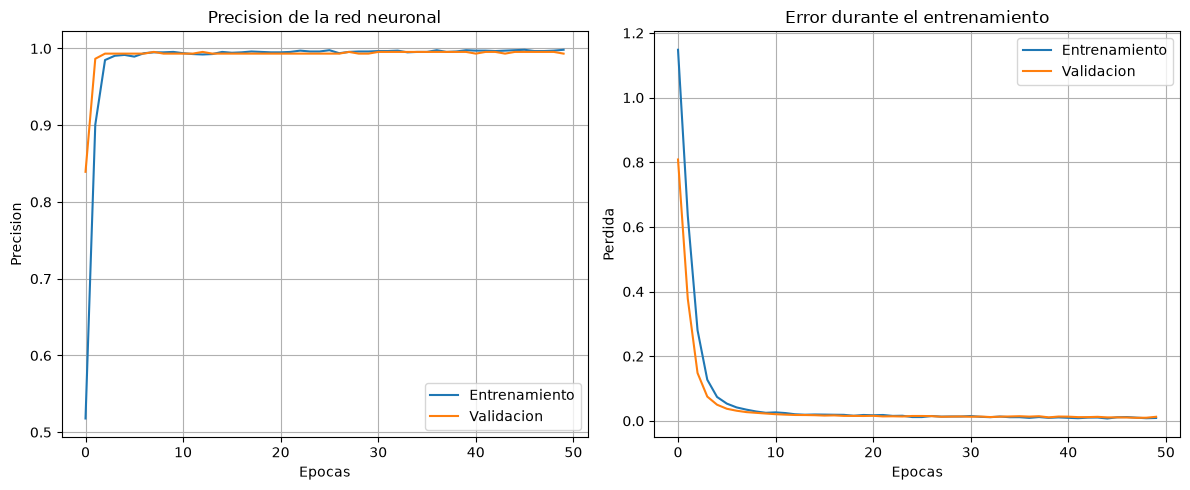

In [ ]:
# Paso 15: Graficas de precision y perdida
plt.figure(figsize=(12, 5))

# Grafica de precision
plt.subplot(1, 2, 1)
plt.plot(historial.history["accuracy"], label="Entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Validacion")
plt.title("Precision de la red neuronal")
plt.xlabel("Epocas")
plt.ylabel("Precision")
plt.legend()
plt.grid()

# Grafica de perdida
plt.subplot(1, 2, 2)
plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validacion")
plt.title("Error durante el entrenamiento")
plt.xlabel("Epocas")
plt.ylabel("Perdida")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

**Identifica:**

- ¿La precisión aumenta conforme avanza el entrenamiento?
- ¿La pérdida disminuye?
- ¿Existe una diferencia importante entre entrenamiento y validación?
- ¿Qué sucedería si el modelo aprendiera demasiado los datos de entrenamiento?

---

## 12. Comprobar qué fallas puede reconocer

**Paso 16.** Generar la matriz de confusión.

Esta herramienta permitirá identificar cuántas veces el modelo clasificó correctamente cada condición y en qué casos se equivocó.


 1/18 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


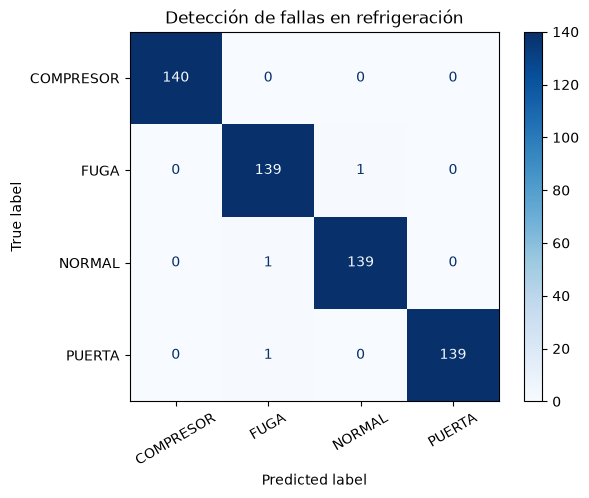

              precision    recall  f1-score   support

   COMPRESOR       1.00      1.00      1.00       140
        FUGA       0.99      0.99      0.99       140
      NORMAL       0.99      0.99      0.99       140
      PUERTA       1.00      0.99      1.00       140

    accuracy                           0.99       560
   macro avg       0.99      0.99      0.99       560
weighted avg       0.99      0.99      0.99       560



In [ ]:
# Paso 16: Matriz de confusion y reporte de clasificacion
# Obtener predicciones
predicciones = modelo.predict(X_test)

# Obtener la clase con mayor probabilidad
predicciones_clase = np.argmax(predicciones, axis=1)

# Crear matriz
matriz = confusion_matrix(y_test, predicciones_clase)

# Mostrar resultados
grafica = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=codificador.classes_,
)
grafica.plot(cmap="Blues", xticks_rotation=30)
plt.title("Detección de fallas en refrigeración")
plt.show()

print(classification_report(
    y_test,
    predicciones_clase,
    target_names=codificador.classes_,
))

**Interpretación:** una matriz de confusión permite observar si el sistema está confundiendo, por ejemplo, una posible falla del compresor con una fuga de refrigerante.

Es especialmente importante revisar los **falsos negativos**: casos en los que existe una condición anormal, pero el modelo la clasifica como normal.

---

## 13. Simulación del diagnóstico de un equipo

Ahora realizaremos una prueba que permitirá demostrar la aplicación práctica de Deep Learning: ingresarás valores de un equipo de refrigeración y la red neuronal determinará a qué condición se parecen más.

**Paso 17.** Crear una función de diagnóstico.

In [15]:
# Paso 17: Funcion de diagnostico de un equipo
def diagnosticar_equipo(temperatura, vibracion, corriente, presion, apertura):
    nuevo = pd.DataFrame([{
        "temperatura": temperatura,
        "vibracion": vibracion,
        "corriente": corriente,
        "presion": presion,
        "apertura": apertura,
    }])

    # Normalizar con el escalador entrenado
    nuevo_escalado = escalador.transform(nuevo)

    # Realizar prediccion
    probabilidades = modelo.predict(nuevo_escalado, verbose=0)[0]

    # Identificar categoria
    indice = np.argmax(probabilidades)
    resultado = codificador.inverse_transform([indice])[0]
    confianza = probabilidades[indice] * 100

    print("\n===== DIAGNOSTICO DEL EQUIPO =====")
    print("Temperatura:", temperatura, "°C")
    print("Vibracion:", vibracion, "mm/s")
    print("Corriente:", corriente, "A")
    print("Presion:", presion, "bar")
    print("Apertura:", apertura, "minutos")
    print("\nCondicion identificada:", resultado)
    print("Confianza del modelo:", round(confianza, 2), "%")

    if resultado == "NORMAL":
        print("RECOMENDACION: Continuar monitoreo.")
    elif resultado == "COMPRESOR":
        print("RECOMENDACION: Solicitar revision tecnica del compresor.")
    elif resultado == "FUGA":
        print("RECOMENDACION: Solicitar inspeccion del circuito refrigerante.")
    elif resultado == "PUERTA":
        print("RECOMENDACION: Revisar cierre, sellos y aislamiento.")

    print("\nProbabilidades por categoria:")
    for nombre, probabilidad in zip(codificador.classes_, probabilidades):
        print(nombre, ":", round(probabilidad * 100, 2), "%")

---

## 14. Realizar pruebas con diferentes escenarios

**Paso 18.** Probar cuatro equipos.

Ejecuta los siguientes ejemplos y observa qué categoría identifica la red neuronal y qué porcentaje de confianza asigna a cada categoría.

> **Importante:** el porcentaje mostrado es la probabilidad estimada por el modelo, no una garantía de que el diagnóstico sea correcto.

In [ ]:
# Prueba A. Equipo funcionando normalmente
diagnosticar_equipo(-20, 2, 8, 2.2, 3)

# Prueba B. Posible problema del compresor
diagnosticar_equipo(-12, 6, 12, 3.1, 4)

# Prueba C. Posible fuga de refrigerante
diagnosticar_equipo(-14, 2.8, 6.5, 1.2, 4)

# Prueba D. Posible problema de puerta o aislamiento
diagnosticar_equipo(-10, 2.2, 8.5, 2.1, 18)


===== DIAGNOSTICO DEL EQUIPO =====
Temperatura: -20 °C
Vibracion: 2 mm/s
Corriente: 8 A
Presion: 2.2 bar
Apertura: 3 minutos

Condicion identificada: NORMAL
Confianza del modelo: 100.0 %
RECOMENDACION: Continuar monitoreo.

Probabilidades por categoria:
COMPRESOR : 0.0 %
FUGA : 0.0 %
NORMAL : 100.0 %
PUERTA : 0.0 %

===== DIAGNOSTICO DEL EQUIPO =====
Temperatura: -12 °C
Vibracion: 6 mm/s
Corriente: 12 A
Presion: 3.1 bar
Apertura: 4 minutos

Condicion identificada: COMPRESOR
Confianza del modelo: 100.0 %
RECOMENDACION: Solicitar revision tecnica del compresor.

Probabilidades por categoria:
COMPRESOR : 100.0 %
FUGA : 0.0 %
NORMAL : 0.0 %
PUERTA : 0.0 %



===== DIAGNOSTICO DEL EQUIPO =====
Temperatura: -14 °C
Vibracion: 2.8 mm/s
Corriente: 6.5 A
Presion: 1.2 bar
Apertura: 4 minutos

Condicion identificada: FUGA
Confianza del modelo: 100.0 %
RECOMENDACION: Solicitar inspeccion del circuito refrigerante.

Probabilidades por categoria:
COMPRESOR : 0.0 %
FUGA : 100.0 %
NORMAL : 0.0 %
PUERTA : 0.0 %



===== DIAGNOSTICO DEL EQUIPO =====
Temperatura: -10 °C
Vibracion: 2.2 mm/s
Corriente: 8.5 A
Presion: 2.1 bar
Apertura: 18 minutos

Condicion identificada: PUERTA
Confianza del modelo: 100.0 %
RECOMENDACION: Revisar cierre, sellos y aislamiento.

Probabilidades por categoria:
COMPRESOR : 0.0 %
FUGA : 0.0 %
NORMAL : 0.0 %
PUERTA : 100.0 %


---

## 15. Actividad complementaria: crear un pequeño panel de control

Para darle mayor sentido empresarial a la práctica, genera un panel gráfico con las condiciones detectadas.

Este código permitirá representar visualmente las probabilidades de clasificación de un equipo:

In [ ]:
# Panel de control: grafico de barras del diagnostico
def graficar_diagnostico(temperatura, vibracion, corriente, presion, apertura):
    nuevo = pd.DataFrame([{
        "temperatura": temperatura,
        "vibracion": vibracion,
        "corriente": corriente,
        "presion": presion,
        "apertura": apertura,
    }])

    datos_escalados = escalador.transform(nuevo)
    probabilidades = modelo.predict(datos_escalados, verbose=0)[0]

    plt.figure(figsize=(9, 5))
    plt.bar(codificador.classes_, probabilidades * 100)
    plt.title("Diagnóstico inteligente de refrigeración")
    plt.ylabel("Probabilidad estimada (%)")
    plt.xlabel("Condiciones del equipo")
    plt.ylim(0, 100)
    plt.grid(axis="y", alpha=0.4)
    plt.show()


graficar_diagnostico(-12, 6, 12, 3.1, 4)

El resultado será una gráfica donde se observará qué condición obtuvo la mayor probabilidad.

---

## 16. Actividad de análisis

Una vez terminada la implementación, responde en tu documento de entrega:

1. ¿Qué es Deep Learning?
2. ¿Cuál es la diferencia entre Machine Learning y Deep Learning?
3. ¿Por qué se utilizaron cinco variables de entrada?
4. ¿Qué función cumplen las capas ocultas?
5. ¿Qué sucedería si se incrementara el número de neuronas?
6. ¿Por qué se dividieron los datos en entrenamiento y prueba?
7. ¿Qué función tiene el algoritmo Adam?
8. ¿Por qué se utiliza Softmax en la última capa?
9. ¿Qué significa que el modelo tenga una precisión del 95%?
10. ¿Qué consecuencias tendría que el modelo clasificara un equipo defectuoso como normal?

---

## 17. Producto de entrega

- [ ] Archivo Google Colab (`.ipynb`) con código completo y ejecutable.
- [ ] Conjunto de datos generado.
- [ ] Gráficas de entrenamiento y validación.
- [ ] Matriz de confusión.
- [ ] Evidencia de las cuatro pruebas de diagnóstico.
- [ ] Video de máximo 3 minutos con grabador de pantalla.
- [ ] Documento PDF con los puntos solicitados y la conclusión.

### Conclusión sobre la utilidad de Deep Learning en el mantenimiento de equipos de refrigeración

> Deep Learning permite transformar datos de operación (temperatura, vibración, corriente, presión y apertura de puerta) en diagnósticos oportunos de las condiciones de los equipos de refrigeración. En lugar de depender únicamente de inspecciones manuales, la red neuronal aprende los patrones asociados a cada falla y avisa de forma inmediata si una condición es anormal, lo que ayuda a evitar la pérdida de alimentos congelados, reducir el consumo eléctrico, prevenir daños en los compresores y disminuir los costos de mantenimiento correctivo. Aunque este prototipo utiliza datos simulados con fines educativos, demuestra el potencial de la inteligencia artificial para el mantenimiento predictivo en la industria.